# ICE Task 3: Pipelines and Text Data
## Amazon Fine Food Reviews: themes and sentiment

**Purpose:** find the main areas of concern and praise in customer reviews, and measure overall sentiment.

**Pipeline:** load and audit, clean, explore, engineer features, train baseline models, improve, extract themes with LDA.

Every number in the report comes from this notebook. Run it top to bottom (Kernel > Restart and Run All).
The full run took about 15 minutes on 2 CPU cores. Set the environment variable `ICE3_SAMPLE`
(for example 30000) to run a quick test on the first N rows.

## 0. Setup

In [1]:
import os, re, json, time, gc, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import (CountVectorizer, TfidfVectorizer,
                                             ENGLISH_STOP_WORDS)
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.dummy import DummyClassifier
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.metrics import (accuracy_score, f1_score, precision_recall_fscore_support,
                             confusion_matrix, roc_auc_score, classification_report)
from wordcloud import WordCloud

warnings.filterwarnings("ignore")

# Paths (relative to the folder that holds this notebook)
ROOT = Path.cwd()
DATA = ROOT / "data" / "Reviews.csv"
FIG = ROOT / "figures"
OUT = ROOT / "outputs"
FIG.mkdir(exist_ok=True)
OUT.mkdir(exist_ok=True)

# Optional quick-test switch: ICE3_SAMPLE=30000 reads only the first 30000 rows
SAMPLE = int(os.environ.get("ICE3_SAMPLE", "0"))
SEED = 42

# Chart style. Two-class colours were checked for colour-blind safety and contrast.
POS, NEG, INK, GREY, LIGHT = "#2F6FDE", "#D9631E", "#0A1D3D", "#6B7280", "#E5E7EB"
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Liberation Sans", "DejaVu Sans"],
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.labelcolor": INK,
    "xtick.color": INK, "ytick.color": INK, "text.color": INK,
    "axes.titleweight": "bold", "axes.titlesize": 10.5, "axes.titlelocation": "left",
    "axes.labelsize": 9, "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
    "legend.frameon": False, "legend.fontsize": 8.5,
    "figure.dpi": 110, "savefig.dpi": 200,
})

# R collects every headline number so the report can quote them exactly
R = {}

def dump():
    """Write all collected results to disk (called after each major section)."""
    with open(OUT / "results.json", "w") as fh:
        json.dump(R, fh, indent=2, default=float)

def save(fig, name):
    """Save a figure at report quality and show it in the notebook."""
    fig.savefig(FIG / name, bbox_inches="tight", facecolor="white")
    plt.show()

## 1. Load and audit the raw data

In [2]:
t0 = time.time()
raw = pd.read_csv(DATA, nrows=SAMPLE or None)
print(f"Loaded {len(raw):,} rows x {raw.shape[1]} columns in {time.time()-t0:.0f}s")
print(raw.dtypes.to_string())
print("\nMissing values per column:")
print(raw.isna().sum().to_string())

R["rows_raw"] = len(raw)
R["products_raw"] = int(raw.ProductId.nunique())
R["users_raw"] = int(raw.UserId.nunique())
ts = pd.to_datetime(raw.Time, unit="s")
R["date_min"], R["date_max"] = str(ts.min().date()), str(ts.max().date())
print(f"\nProducts: {R['products_raw']:,}   Reviewers: {R['users_raw']:,}   Period: {R['date_min']} to {R['date_max']}")
print("\nStar rating distribution (raw):")
print((raw.Score.value_counts(normalize=True).sort_index() * 100).round(1).to_string())

Loaded 568,454 rows x 10 columns in 5s
Id                        int64
ProductId                   str
UserId                      str
ProfileName                 str
HelpfulnessNumerator      int64
HelpfulnessDenominator    int64
Score                     int64
Time                      int64
Summary                     str
Text                        str

Missing values per column:


Id                         0
ProductId                  0
UserId                     0
ProfileName               26
HelpfulnessNumerator       0
HelpfulnessDenominator     0
Score                      0
Time                       0
Summary                   27
Text                       0

Products: 74,258   Reviewers: 256,059   Period: 1999-10-08 to 2012-10-26

Star rating distribution (raw):
Score
1     9.2
2     5.2
3     7.5
4    14.2
5    63.9


## 2. Data cleaning
Plan: handle missing values, fix impossible helpfulness counts, remove duplicate reviews, build the sentiment label, normalize text.

In [3]:
log = {"rows_raw": len(raw)}

# 2.1 Missing values. Text is never missing. Summary is missing in a handful of rows: keep the review, use empty summary.
# ProfileName is not used anywhere in this analysis, so its gaps are harmless.
log["missing_text"] = int(raw.Text.isna().sum())
log["missing_summary"] = int(raw.Summary.isna().sum())
log["missing_profilename"] = int(raw.ProfileName.isna().sum())
df = raw.dropna(subset=["Text"]).copy()
df["Summary"] = df["Summary"].fillna("")

# 2.2 Impossible helpfulness counts (more helpful votes than total votes)
bad = df.HelpfulnessNumerator > df.HelpfulnessDenominator
log["bad_helpfulness_removed"] = int(bad.sum())
df = df[~bad]

# 2.3 Duplicates. The same reviewer posting the same text at the same time is one review copied across product variants.
# Keeping copies would inflate counts and leak identical text into both train and test sets.
n_before = len(df)
df = df.drop_duplicates(subset=["UserId", "Time", "Text"], keep="first")
log["duplicates_removed"] = n_before - len(df)

# Remaining identical texts from different reviewers or times: check what they are before deciding to keep them
rep = df[df.duplicated(subset=["Text"], keep=False)]
log["remaining_repeat_text_rows"] = len(rep)
log["remaining_repeat_median_words"] = float(rep.Text.str.split().str.len().median()) if len(rep) else 0.0

del raw
gc.collect()
print(f"Duplicates removed: {log['duplicates_removed']:,} ({log['duplicates_removed']/log['rows_raw']*100:.1f}% of raw rows)")
print(f"Rows still sharing identical text with another row: {log['remaining_repeat_text_rows']:,} "
      f"(median {log['remaining_repeat_median_words']:.0f} words); kept, because they come from different reviewers or dates")

# 2.4 Sentiment label from star rating: 4-5 positive (1), 1-2 negative (0), 3 neutral (excluded from model training)
df["label"] = np.select([df.Score >= 4, df.Score <= 2], [1, 0], default=-1)
df["review"] = df["Summary"] + ". " + df["Text"]   # Summary and body together form the customer's full voice
df["year"] = pd.to_datetime(df.Time, unit="s").dt.year
df["n_words"] = df["Text"].str.split().str.len()

Duplicates removed: 174,562 (30.7% of raw rows)
Rows still sharing identical text with another row: 582 (median 148 words); kept, because they come from different reviewers or dates


### Text normalization
Lowercase, strip HTML and URLs, expand negative contractions (so "didn't" becomes "did not"), remove punctuation and digits,
then drop stop words. Negation words are deliberately **kept**, because "not good" and "good" mean opposite things.

In [4]:
NEGATIONS = {"not", "no", "nor", "never", "nothing", "nobody", "none", "cannot", "without", "neither"}
STOP = (set(ENGLISH_STOP_WORDS) - NEGATIONS) | {"br"}

def clean(text):
    """Return a normalized, stop-word-free version of one review."""
    t = text.lower().replace("\u2019", "'")                 # lowercase and straighten apostrophes
    t = re.sub(r"<[^>]+>", " ", t)                          # remove HTML tags such as <br />
    t = re.sub(r"http\S+|www\.\S+", " ", t)                 # remove URLs
    t = t.replace("won't", "will not").replace("can't", "can not").replace("n't", " not")  # keep negation
    t = re.sub(r"[^a-z\s]", " ", t)                         # remove punctuation and digits
    return " ".join(w for w in t.split() if len(w) > 1 and w not in STOP)

# Worked example on two real reviews so the effect is visible
for i in (1, 3):
    print("RAW  :", df.Text.iloc[i][:230])
    print("CLEAN:", clean(df.Summary.iloc[i] + ". " + df.Text.iloc[i])[:230], "\n")

t0 = time.time()
df["clean"] = [clean(t) for t in df["review"]]
print(f"Normalized {len(df):,} reviews in {time.time()-t0:.0f}s")

# Reviews that are empty after cleaning cannot be modelled
empty = df["clean"].str.len() == 0
log["empty_after_cleaning"] = int(empty.sum())
df = df[~empty].reset_index(drop=True)
log["rows_clean"] = len(df)
R["cleaning"] = log
R["rows_clean"] = len(df)
print(f"Dropped {log['empty_after_cleaning']} empty reviews. Clean dataset: {len(df):,} rows")
dump()

RAW  : Product arrived labeled as Jumbo Salted Peanuts...the peanuts were actually small sized unsalted. Not sure if this was an error or if the vendor intended to represent the product as "Jumbo".
CLEAN: not advertised product arrived labeled jumbo salted peanuts peanuts actually small sized unsalted not sure error vendor intended represent product jumbo 

RAW  : If you are looking for the secret ingredient in Robitussin I believe I have found it.  I got this in addition to the Root Beer Extract I ordered (which was good) and made some cherry soda.  The flavor is very medicinal.
CLEAN: cough medicine looking secret ingredient robitussin believe got addition root beer extract ordered good cherry soda flavor medicinal 



Normalized 393,890 reviews in 13s


Dropped 2 empty reviews. Clean dataset: 393,888 rows


## 3. Exploratory data analysis

{'negative': 57103, 'neutral': 29768, 'positive': 307017} | negative share of labelled reviews: 15.7%


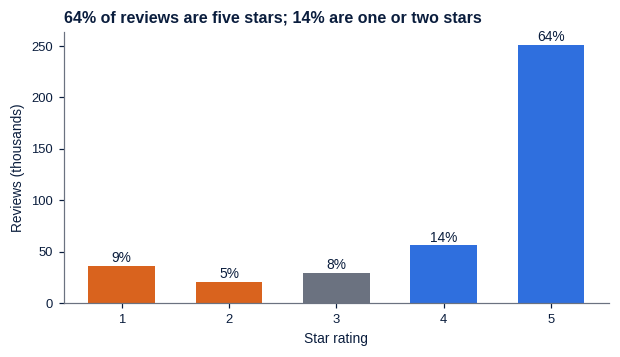

In [5]:
# 3.1 Star rating and sentiment class balance
counts = df.Score.value_counts().sort_index()
share = counts / counts.sum() * 100
R["score_share_pct"] = {int(k): float(v) for k, v in share.items()}
R["score_counts"] = {int(k): int(v) for k, v in counts.items()}
n_neg = int((df.label == 0).sum()); n_pos = int((df.label == 1).sum()); n_neu = int((df.label == -1).sum())
R["class_counts"] = {"negative": n_neg, "neutral": n_neu, "positive": n_pos}
R["negative_share_of_labelled_pct"] = n_neg / (n_neg + n_pos) * 100
print(R["class_counts"], f"| negative share of labelled reviews: {R['negative_share_of_labelled_pct']:.1f}%")

fig, ax = plt.subplots(figsize=(6.4, 3.2))
cols = [NEG, NEG, GREY, POS, POS]
ax.bar(counts.index, counts.values / 1000, color=cols, width=0.62)
for x, v, s in zip(counts.index, counts.values / 1000, share.values):
    ax.text(x, v + counts.max() / 1000 * 0.015, f"{s:.0f}%", ha="center", fontsize=9)
ax.set_xlabel("Star rating"); ax.set_ylabel("Reviews (thousands)")
ax.set_title(f"{share[5]:.0f}% of reviews are five stars; {share[1] + share[2]:.0f}% are one or two stars")
save(fig, "fig01_score_distribution.png")

           n    neg   avg
year                     
2005    1069   8.33  4.50
2006    4748  12.43  4.30
2007   15778   9.99  4.39
2008   23129  10.39  4.34
2009   37891  11.95  4.28
2010   58003  13.97  4.21
2011  113486  15.30  4.14
2012  139178  16.10  4.11


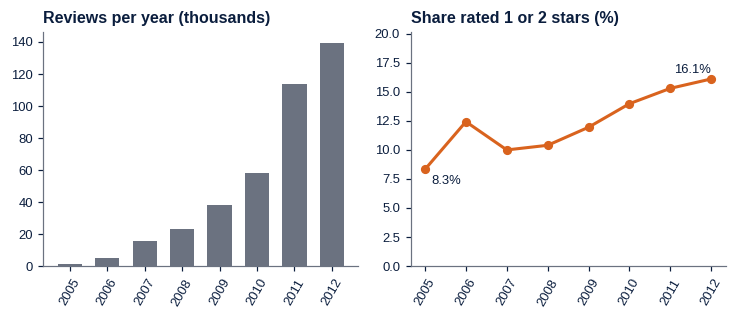

In [6]:
# 3.2 Trend over time (only years with at least 1,000 reviews, so small early years do not distort the line)
yr = df.groupby("year").agg(n=("Score", "size"), neg=("Score", lambda s: (s <= 2).mean() * 100),
                            avg=("Score", "mean"))
yr = yr[yr.n >= 1000]
R["by_year"] = {int(k): {"reviews": int(r.n), "neg_pct": float(r.neg), "avg_score": float(r.avg)} for k, r in yr.iterrows()}
print(yr.round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(6.8, 3.0))
axes[0].bar(yr.index, yr.n / 1000, color=GREY, width=0.65)
axes[0].set_title("Reviews per year (thousands)"); axes[0].set_xticks(yr.index); axes[0].tick_params(axis="x", rotation=60)
axes[1].plot(yr.index, yr.neg, color=NEG, lw=2, marker="o", ms=5)
axes[1].set_title("Share rated 1 or 2 stars (%)"); axes[1].set_xticks(yr.index); axes[1].tick_params(axis="x", rotation=60)
axes[1].set_ylim(0, max(yr.neg) * 1.25)
axes[1].text(yr.index[0] + 0.15, yr.neg.iloc[0] - 1.3, f"{yr.neg.iloc[0]:.1f}%", color=INK, fontsize=8.5)
axes[1].text(yr.index[-1], yr.neg.iloc[-1] + 0.5, f"{yr.neg.iloc[-1]:.1f}%", color=INK, fontsize=8.5, ha="right")
fig.tight_layout()
save(fig, "fig02_trend_by_year.png")

{'mean': 79.83247522138272, 'median': 57.0, 'p99': 378.0, 'median_pos': 54.0, 'median_neg': 63.0, 'max': 3432}


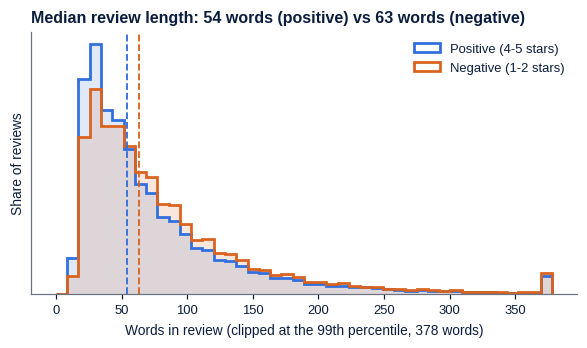

In [7]:
# 3.3 Review length distribution (words in the review body)
lab = df[df.label >= 0]
cap = float(np.percentile(df.n_words, 99))          # clip the long tail so the bulk of the data is readable
med_all, med_pos, med_neg = df.n_words.median(), lab[lab.label == 1].n_words.median(), lab[lab.label == 0].n_words.median()
R["length"] = {"mean": float(df.n_words.mean()), "median": float(med_all), "p99": cap,
               "median_pos": float(med_pos), "median_neg": float(med_neg), "max": int(df.n_words.max())}
print(R["length"])

bins = np.linspace(0, cap, 45)
fig, ax = plt.subplots(figsize=(6.4, 3.1))
for lbl, colr, nm in ((1, POS, "Positive (4-5 stars)"), (0, NEG, "Negative (1-2 stars)")):
    vals = lab[lab.label == lbl].n_words.clip(upper=cap)          # the last bar holds every review longer than the cap
    ax.hist(vals, bins=bins, density=True, color=colr, alpha=0.15, histtype="stepfilled")
    ax.hist(vals, bins=bins, density=True, color=colr, lw=1.8, histtype="step", label=nm)
ax.axvline(med_pos, color=POS, ls="--", lw=1.2); ax.axvline(med_neg, color=NEG, ls="--", lw=1.2)
ax.set_xlabel(f"Words in review (clipped at the 99th percentile, {cap:.0f} words)"); ax.set_ylabel("Share of reviews")
ax.set_yticks([])
ax.set_title(f"Median review length: {med_pos:.0f} words (positive) vs {med_neg:.0f} words (negative)")
ax.legend(loc="upper right")
save(fig, "fig03_review_length.png")

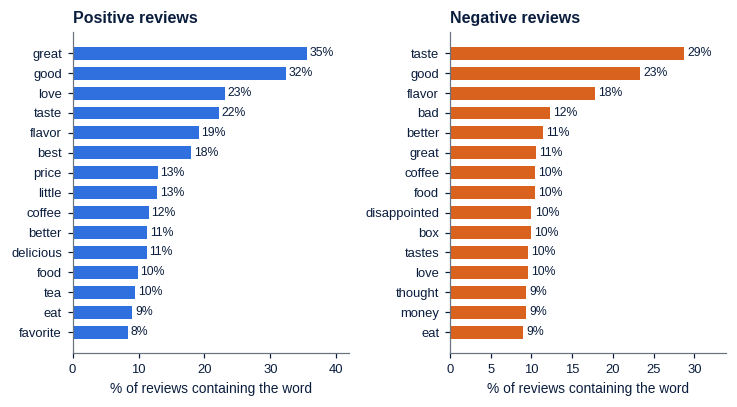

In [8]:
# 3.4 Word frequency: share of reviews that contain each word (document frequency), by sentiment
def doc_freq(series):
    c = Counter()
    for t in series:
        c.update(set(t.split()))        # count each word once per review
    return c

pos_text, neg_text = df.loc[df.label == 1, "clean"], df.loc[df.label == 0, "clean"]
dfp, dfn = doc_freq(pos_text), doc_freq(neg_text)
Np, Nn = len(pos_text), len(neg_text)

# For the CHARTS ONLY, hide negations and everyday filler so the informative words are visible.
# (Negations stay in the data because the model needs them: "not good" is not "good".)
EDA_HIDE = NEGATIONS | {"like", "just", "really", "one", "get", "got", "would", "also", "even", "much", "use", "used",
                        "buy", "bought", "product", "products", "amazon", "time", "make", "made", "did", "does", "way",
                        "lot", "ve", "ll", "try", "tried", "think", "going", "ordered", "order", "want", "know", "say",
                        "said", "review", "reviews", "item", "items", "got", "thing", "things", "didn", "don", "doesn"}
def shown(counter, n):
    """Most common words in a document-frequency counter, skipping the hidden words."""
    return [(w, c) for w, c in counter.most_common(n * 4) if w not in EDA_HIDE][:n]

top_p = [(w, c / Np * 100) for w, c in shown(dfp, 15)]
top_n = [(w, c / Nn * 100) for w, c in shown(dfn, 15)]
R["top_words_pos"] = [(w, float(v)) for w, v in top_p]
R["top_words_neg"] = [(w, float(v)) for w, v in top_n]

fig, axes = plt.subplots(1, 2, figsize=(6.8, 3.8))
for ax, data, colr, ttl in ((axes[0], top_p, POS, "Positive reviews"), (axes[1], top_n, NEG, "Negative reviews")):
    ws, vs = zip(*data[::-1])
    ax.barh(ws, vs, color=colr, height=0.65)
    for y, v in enumerate(vs):
        ax.text(v + 0.4, y, f"{v:.0f}%", va="center", fontsize=8)
    ax.set_title(ttl); ax.set_xlabel("% of reviews containing the word")
    ax.set_xlim(0, max(vs) * 1.18)
fig.tight_layout()
save(fig, "fig04_top_words.png")

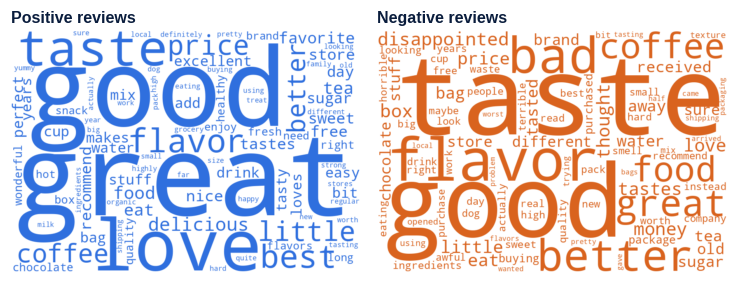

In [9]:
# 3.5 Word clouds (size = share of reviews containing the word; negations and filler hidden, as above)
fig, axes = plt.subplots(1, 2, figsize=(6.8, 2.9))
for ax, counter, colr, ttl in ((axes[0], dfp, POS, "Positive reviews"), (axes[1], dfn, NEG, "Negative reviews")):
    wc = WordCloud(width=900, height=620, background_color="white", max_words=90, prefer_horizontal=0.95,
                   color_func=lambda *a, _c=colr, **k: _c, random_state=SEED)
    wc.generate_from_frequencies(dict(shown(counter, 150)))
    ax.imshow(wc, interpolation="bilinear"); ax.axis("off"); ax.set_title(ttl)
fig.tight_layout()
save(fig, "fig05_wordclouds.png")

Complaint words: yuck (25x), worst (24x), refund (24x), disappointing (22x), disappointment (17x), disgusting (17x), threw (16x), awful (15x), horrible (14x), misleading (14x), terrible (14x), return (13x), trash (12x), beware (11x)
Praise words   : yum (14x), hooked (13x), pleasantly (13x), versatile (11x), yummy (8x), downside (8x), addictive (7x), guilt (7x), salads (7x), beat (6x), perfect (6x), saves (6x), awesome (6x), delicious (6x)


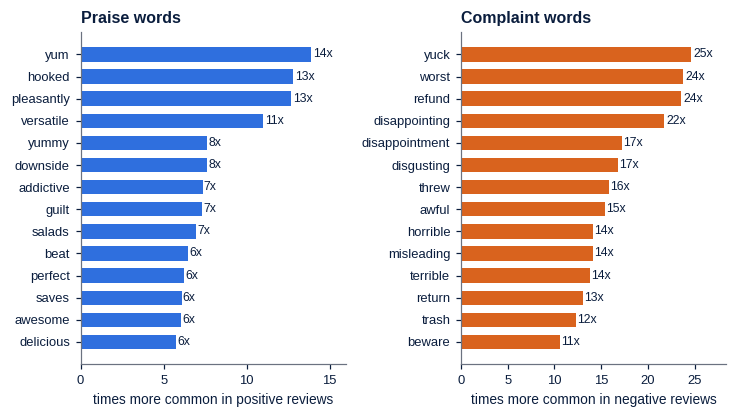

In [10]:
# 3.6 Words that separate complaints from praise: how many times more common a word is in one group than the other
vocab_all = set(dfp) | set(dfn)
rows = []
for w in vocab_all:
    cp, cn = dfp.get(w, 0), dfn.get(w, 0)
    if cp + cn >= 1000:                                 # ignore rare words so the list reflects patterns, not quirks
        rows.append((w, cn, cp, ((cn + 1) / Nn) / ((cp + 1) / Np)))
dist = pd.DataFrame(rows, columns=["word", "neg_reviews", "pos_reviews", "neg_over_pos"])
comp = dist.sort_values("neg_over_pos", ascending=False).head(14)
prai = dist.assign(pos_over_neg=1 / dist.neg_over_pos).sort_values("pos_over_neg", ascending=False).head(14)
R["distinctive_complaint_words"] = [(r.word, float(r.neg_over_pos), int(r.neg_reviews)) for r in comp.itertuples()]
R["distinctive_praise_words"] = [(r.word, float(r.pos_over_neg), int(r.pos_reviews)) for r in prai.itertuples()]
print("Complaint words:", ", ".join(f"{w} ({v:.0f}x)" for w, v, _ in R["distinctive_complaint_words"]))
print("Praise words   :", ", ".join(f"{w} ({v:.0f}x)" for w, v, _ in R["distinctive_praise_words"]))

fig, axes = plt.subplots(1, 2, figsize=(6.8, 3.9))
axes[0].barh(prai.word[::-1], prai.pos_over_neg[::-1], color=POS, height=0.65)
axes[0].set_title("Praise words"); axes[0].set_xlabel("times more common in positive reviews")
axes[1].barh(comp.word[::-1], comp.neg_over_pos[::-1], color=NEG, height=0.65)
axes[1].set_title("Complaint words"); axes[1].set_xlabel("times more common in negative reviews")
for ax, vals in ((axes[0], prai.pos_over_neg[::-1]), (axes[1], comp.neg_over_pos[::-1])):
    for y, v in enumerate(vals):
        ax.text(v * 1.01, y, f"{v:.0f}x", va="center", fontsize=8)
    ax.set_xlim(0, vals.max() * 1.15)
fig.tight_layout()
save(fig, "fig06_distinctive_words.png")

Baseline: 14.5% of all reviews are 1-2 stars
                aspect  mentions  pct_of_reviews  neg_rate_pct  pos_rate_pct
  Packaging and damage     69695            17.7          20.7          69.3
  Freshness and expiry     46363            11.8          17.7          75.0
       Price and value    103231            26.2          16.4          75.6
 Delivery and shipping     47352            12.0          15.5          77.6
              Pet food     38825             9.9          14.9          78.1
     Taste and flavour    214638            54.5          13.8          77.7
Ingredients and health    104151            26.4          12.7          79.6


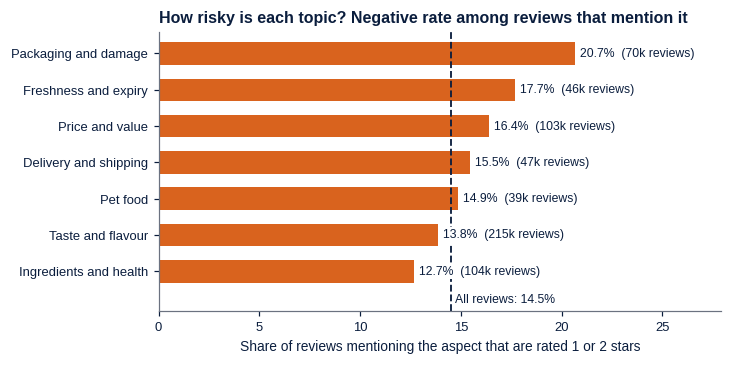

In [11]:
# 3.7 Business aspects. A keyword dictionary (defined by me, listed here so it can be audited) flags which reviews mention each aspect.
ASPECTS = {
    "Taste and flavour":      r"\b(taste|tastes|tasted|tasting|flavor|flavors|flavour|bland|bitter|sweet|salty|aftertaste|delicious|tasteless)\b",
    "Packaging and damage":   r"\b(package|packaging|packaged|packed|box|boxes|damaged|broken|leaked|leaking|leak|crushed|dented|seal|sealed|opened)\b",
    "Delivery and shipping":  r"\b(shipping|shipped|ship|delivery|delivered|arrived|arrive|arrives|late|delay|delayed|seller|vendor)\b",
    "Price and value":        r"\b(price|priced|prices|cost|costs|expensive|cheap|cheaper|overpriced|worth|value|money|paid|pay)\b",
    "Freshness and expiry":   r"\b(stale|fresh|freshness|expired|expiration|expiry|rancid|moldy|mold|spoiled|rotten|old)\b",
    "Ingredients and health": r"\b(organic|natural|ingredients|ingredient|sugar|healthy|health|preservatives|artificial|gluten|calories|chemicals)\b",
    "Pet food":               r"\b(dog|dogs|cat|cats|puppy|kitten|pet|pets)\b",
}
base_neg = (df.Score <= 2).mean() * 100
R["baseline_negative_pct_all"] = float(base_neg)
rows = []
for name, pat in ASPECTS.items():
    mask = df["clean"].str.contains(pat, regex=True)
    rows.append((name, int(mask.sum()), mask.mean() * 100, (df.Score[mask] <= 2).mean() * 100,
                 (df.Score[mask] >= 4).mean() * 100))
asp = pd.DataFrame(rows, columns=["aspect", "mentions", "pct_of_reviews", "neg_rate_pct", "pos_rate_pct"]).sort_values("neg_rate_pct", ascending=False)
R["aspects"] = asp.to_dict(orient="records")
print(f"Baseline: {base_neg:.1f}% of all reviews are 1-2 stars")
print(asp.round(1).to_string(index=False))

fig, ax = plt.subplots(figsize=(6.6, 3.3))
a = asp.iloc[::-1]
ax.barh(a.aspect, a.neg_rate_pct, color=NEG, height=0.62)
for y, (v, n) in enumerate(zip(a.neg_rate_pct, a.mentions)):
    ax.text(v + 0.25, y, f"{v:.1f}%  ({n/1000:.0f}k reviews)", va="center", fontsize=8, zorder=3,
            bbox=dict(facecolor="white", edgecolor="none", pad=1.2))
ax.axvline(base_neg, color=INK, ls="--", lw=1.2, zorder=1)
ax.set_ylim(-1.1, len(a) - 0.4)
ax.text(base_neg + 0.2, -0.85, f"All reviews: {base_neg:.1f}%", fontsize=8, color=INK)
ax.set_xlim(0, a.neg_rate_pct.max() * 1.35)
ax.set_xlabel("Share of reviews mentioning the aspect that are rated 1 or 2 stars")
ax.set_title("How risky is each topic? Negative rate among reviews that mention it")
save(fig, "fig07_aspect_risk.png")
dump()

## 4. Feature engineering
Models cannot read words, so each review becomes a row of numbers. We compare four representations on a validation slice cut
from the **training** data only, so the test set stays untouched until the final evaluation.

In [12]:
# 4.1 Train/test split. Stratified so both sets keep the same positive/negative mix. Neutral (3-star) reviews are held out.
sent = df[df.label >= 0].reset_index(drop=True)
train_df, test_df = train_test_split(sent, test_size=0.20, stratify=sent.label, random_state=SEED)
y_tr, y_te = train_df.label.values, test_df.label.values
R["split"] = {"train": len(train_df), "test": len(test_df), "train_neg_pct": float((y_tr == 0).mean() * 100),
              "test_neg_pct": float((y_te == 0).mean() * 100)}
print(R["split"])

def metrics(name, y_true, y_pred, score=None):
    """Collect accuracy, per-class precision/recall/F1, macro-F1, AUC and the confusion matrix for one model."""
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=[0, 1], zero_division=0)
    acc = accuracy_score(y_true, y_pred)
    return {"model": name, "accuracy": acc, "macro_f1": f1_score(y_true, y_pred, average="macro"),
            "neg_precision": p[0], "neg_recall": r[0], "neg_f1": f[0],
            "pos_precision": p[1], "pos_recall": r[1], "pos_f1": f[1],
            "auc": roc_auc_score(y_true, score) if score is not None else None,
            "cm": confusion_matrix(y_true, y_pred, labels=[0, 1]).tolist(),
            "acc_ci95": 1.96 * np.sqrt(acc * (1 - acc) / len(y_true))}

{'train': 291296, 'test': 72824, 'train_neg_pct': 15.682330001098538, 'test_neg_pct': 15.683016587938042}


In [13]:
# 4.2 Compare feature representations on a validation slice of the training data
rng_idx = np.random.RandomState(1).choice(len(train_df), size=min(120000, len(train_df)), replace=False)
sub = train_df.iloc[rng_idx]
in_tr, in_va = train_test_split(sub, test_size=0.2, stratify=sub.label, random_state=SEED)

configs = {
    "Bag of words, single words (20k)":      lambda: CountVectorizer(min_df=5, max_features=20000),
    "TF-IDF, single words (20k)":            lambda: TfidfVectorizer(min_df=5, max_features=20000, sublinear_tf=True),
    "TF-IDF, 1-2 word phrases (20k)":        lambda: TfidfVectorizer(min_df=5, max_features=20000, ngram_range=(1, 2), sublinear_tf=True),
    "TF-IDF, 1-2 word phrases (100k)":       lambda: TfidfVectorizer(min_df=5, max_features=100000, ngram_range=(1, 2), sublinear_tf=True),
}
rows = []
for name, make in configs.items():
    t0 = time.time()
    v = make()
    Xa = v.fit_transform(in_tr.clean); Xb = v.transform(in_va.clean)      # vocabulary learned from the training slice only
    best_row = None
    # Same classifier for every representation, with C tuned for each so no representation is handicapped by its scaling
    for C in (1, 5, 20):
        m = LogisticRegression(C=C, class_weight="balanced", max_iter=1000).fit(Xa, in_tr.label)
        pr = m.predict(Xb)
        cand = {"features": name, "n_features": Xa.shape[1], "best_C": C,
                "accuracy": accuracy_score(in_va.label, pr),
                "macro_f1": f1_score(in_va.label, pr, average="macro"),
                "neg_f1": f1_score(in_va.label, pr, pos_label=0)}
        if best_row is None or cand["macro_f1"] > best_row["macro_f1"]:
            best_row = cand
    best_row["seconds"] = time.time() - t0
    rows.append(best_row)
    print(f"  done: {name}  best C={best_row['best_C']}  macro-F1={best_row['macro_f1']:.4f}  ({best_row['seconds']:.0f}s)")
feat_cmp = pd.DataFrame(rows)
R["feature_comparison"] = feat_cmp.to_dict(orient="records")
print(feat_cmp.round(4).to_string(index=False))
dump()

  done: Bag of words, single words (20k)  best C=1  macro-F1=0.8621  (31s)


  done: TF-IDF, single words (20k)  best C=5  macro-F1=0.8661  (8s)


  done: TF-IDF, 1-2 word phrases (20k)  best C=5  macro-F1=0.8929  (23s)


  done: TF-IDF, 1-2 word phrases (100k)  best C=20  macro-F1=0.9025  (27s)
                        features  n_features  best_C  accuracy  macro_f1  neg_f1  seconds
Bag of words, single words (20k)       18160       1    0.9210    0.8621  0.7720  30.8938
      TF-IDF, single words (20k)       18160       5    0.9218    0.8661  0.7798   7.6458
  TF-IDF, 1-2 word phrases (20k)       20000       5    0.9392    0.8929  0.8225  23.4860
 TF-IDF, 1-2 word phrases (100k)      100000      20    0.9467    0.9025  0.8369  26.8072


## 5. Model training: baselines
**Baseline settings fixed in advance (the analysis plan):** TF-IDF on single words, `max_features=20000`, `min_df=5`.
Logistic Regression `C=1.0`; Multinomial Naive Bayes `alpha=1.0`. A majority-class "model" shows what accuracy alone hides.

In [14]:
t0 = time.time()
vec1 = TfidfVectorizer(min_df=5, max_features=20000, sublinear_tf=True)
X1_tr = vec1.fit_transform(train_df.clean)       # learn vocabulary and IDF weights from training reviews only
X1_te = vec1.transform(test_df.clean)
print(f"v1 features: {X1_tr.shape[1]:,} columns, built in {time.time()-t0:.0f}s")

all_results = []

dummy = DummyClassifier(strategy="most_frequent").fit(X1_tr, y_tr)
all_results.append(metrics("Majority-class guess", y_te, dummy.predict(X1_te)))

nb1 = MultinomialNB(alpha=1.0).fit(X1_tr, y_tr)
all_results.append(metrics("Naive Bayes (v1)", y_te, nb1.predict(X1_te), nb1.predict_proba(X1_te)[:, 1]))

t0 = time.time()
lr1 = LogisticRegression(C=1.0, max_iter=1000).fit(X1_tr, y_tr)
print(f"Logistic Regression v1 trained in {time.time()-t0:.0f}s, iterations used: {int(lr1.n_iter_[0])}")
pred1 = lr1.predict(X1_te)
all_results.append(metrics("Logistic Regression (v1 baseline)", y_te, pred1, lr1.decision_function(X1_te)))

for r in all_results:
    print(f"{r['model']:<36} acc={r['accuracy']:.4f}  macroF1={r['macro_f1']:.4f}  neg P/R/F1={r['neg_precision']:.3f}/{r['neg_recall']:.3f}/{r['neg_f1']:.3f}")
print("\nLogistic Regression v1 full report:")
print(classification_report(y_te, pred1, target_names=["negative", "positive"], digits=3))

v1 features: 20,000 columns, built in 14s


Logistic Regression v1 trained in 4s, iterations used: 43
Majority-class guess                 acc=0.8432  macroF1=0.4575  neg P/R/F1=0.000/0.000/0.000
Naive Bayes (v1)                     acc=0.8935  macroF1=0.7280  neg P/R/F1=0.899/0.362/0.516
Logistic Regression (v1 baseline)    acc=0.9418  macroF1=0.8826  neg P/R/F1=0.872/0.738/0.799

Logistic Regression v1 full report:
              precision    recall  f1-score   support

    negative      0.872     0.738     0.799     11421
    positive      0.953     0.980     0.966     61403

    accuracy                          0.942     72824
   macro avg      0.912     0.859     0.883     72824
weighted avg      0.940     0.942     0.940     72824



## 6. Model improvement
**What changes:** (1) 1-2 word phrases so "not good" and "too sweet" become features; (2) a larger feature cap;
(3) hyperparameters chosen on a validation slice of the training data (regularization strength `C`, and class weighting
because only a minority of reviews are negative). Linear SVM and Naive Bayes are tuned the same way for a fair comparison.

In [15]:
t0 = time.time()
vec2 = TfidfVectorizer(min_df=5, max_features=200000, ngram_range=(1, 2), sublinear_tf=True)
X2_tr = vec2.fit_transform(train_df.clean)
X2_te = vec2.transform(test_df.clean)
print(f"v2 features: {X2_tr.shape[1]:,} columns, built in {time.time()-t0:.0f}s")

# Validation slice inside the training data (the test set is not touched during tuning).
# Note: the vectorizer saw these rows when learning vocabulary/IDF, but never their labels and never any test rows.
idx = np.random.RandomState(7).choice(X2_tr.shape[0], size=min(120000, X2_tr.shape[0]), replace=False)
i_tr, i_va = train_test_split(idx, test_size=0.2, stratify=y_tr[idx], random_state=SEED)

def val_score(model):
    """Fit on the tuning-train slice, return macro-F1 on the tuning-validation slice."""
    model.fit(X2_tr[i_tr], y_tr[i_tr])
    return f1_score(y_tr[i_va], model.predict(X2_tr[i_va]), average="macro")

grid_rows = []
for C in (0.5, 1, 5, 20):
    for cw in (None, "balanced"):
        grid_rows.append(("Logistic Regression", f"C={C}, class_weight={cw}", C, str(cw),
                          val_score(LogisticRegression(C=C, class_weight=cw, max_iter=1000))))
for C in (0.1, 0.3, 1):
    for cw in (None, "balanced"):
        grid_rows.append(("Linear SVM", f"C={C}, class_weight={cw}", C, str(cw),
                          val_score(LinearSVC(C=C, class_weight=cw))))
for a in (0.05, 0.1, 0.3, 1.0):
    grid_rows.append(("Naive Bayes", f"alpha={a}", a, "None", val_score(MultinomialNB(alpha=a))))
grid = pd.DataFrame(grid_rows, columns=["family", "setting", "p1", "p2", "val_macro_f1"])
print(grid[["family", "setting", "val_macro_f1"]].round(4).to_string(index=False))
best = grid.loc[grid.groupby("family").val_macro_f1.idxmax()].set_index("family")
R["tuning_grid"] = grid[["family", "setting", "val_macro_f1"]].to_dict(orient="records")
R["best_settings"] = {f: r.setting for f, r in best.iterrows()}
print("\nBest per family:", R["best_settings"], f"(tuning took {time.time()-t0:.0f}s)")

v2 features: 200,000 columns, built in 59s


             family                      setting  val_macro_f1
Logistic Regression     C=0.5, class_weight=None        0.8529
Logistic Regression C=0.5, class_weight=balanced        0.8800
Logistic Regression       C=1, class_weight=None        0.8764
Logistic Regression   C=1, class_weight=balanced        0.8895
Logistic Regression       C=5, class_weight=None        0.8994
Logistic Regression   C=5, class_weight=balanced        0.9015
Logistic Regression      C=20, class_weight=None        0.9050
Logistic Regression  C=20, class_weight=balanced        0.9034
         Linear SVM     C=0.1, class_weight=None        0.8815
         Linear SVM C=0.1, class_weight=balanced        0.8924
         Linear SVM     C=0.3, class_weight=None        0.9021
         Linear SVM C=0.3, class_weight=balanced        0.9033
         Linear SVM       C=1, class_weight=None        0.9048
         Linear SVM   C=1, class_weight=balanced        0.9068
        Naive Bayes                   alpha=0.05       

In [16]:
# Refit each tuned model on the FULL training set and score once on the test set
bl, bs, bn = best.loc["Logistic Regression"], best.loc["Linear SVM"], best.loc["Naive Bayes"]
# class weight was stored as text in the grid; convert back to None / "balanced"
cw_lr = None if bl.p2 == "None" else bl.p2
cw_svm = None if bs.p2 == "None" else bs.p2

t0 = time.time()
lr2 = LogisticRegression(C=bl.p1, class_weight=cw_lr, max_iter=1000).fit(X2_tr, y_tr)
print(f"Logistic Regression v2 trained in {time.time()-t0:.0f}s, iterations: {int(lr2.n_iter_[0])}")
pred2 = lr2.predict(X2_te)
res_lr2 = metrics("Logistic Regression (v2 improved)", y_te, pred2, lr2.decision_function(X2_te))

svm2 = LinearSVC(C=bs.p1, class_weight=cw_svm).fit(X2_tr, y_tr)
res_svm = metrics("Linear SVM (tuned)", y_te, svm2.predict(X2_te), svm2.decision_function(X2_te))

nb2 = MultinomialNB(alpha=bn.p1).fit(X2_tr, y_tr)
res_nb2 = metrics("Naive Bayes (tuned)", y_te, nb2.predict(X2_te), nb2.predict_proba(X2_te)[:, 1])

all_results += [res_nb2, res_svm, res_lr2]
comp_tbl = pd.DataFrame([{k: v for k, v in r.items() if k not in ("cm",)} for r in all_results])
print(comp_tbl.round(4).to_string(index=False))
print("\nLogistic Regression v2 full report:")
print(classification_report(y_te, pred2, target_names=["negative", "positive"], digits=3))
R["results"] = all_results
R["final_model"] = "Logistic Regression (v2 improved)"
dump()

Logistic Regression v2 trained in 11s, iterations: 53


                            model  accuracy  macro_f1  neg_precision  neg_recall  neg_f1  pos_precision  pos_recall  pos_f1    auc  acc_ci95
             Majority-class guess    0.8432    0.4575         0.0000      0.0000  0.0000         0.8432      1.0000  0.9149    NaN    0.0026
                 Naive Bayes (v1)    0.8935    0.7280         0.8987      0.3618  0.5159         0.8932      0.9924  0.9402 0.9479    0.0022
Logistic Regression (v1 baseline)    0.9418    0.8826         0.8717      0.7377  0.7991         0.9526      0.9798  0.9660 0.9726    0.0017
              Naive Bayes (tuned)    0.9297    0.8493         0.8833      0.6356  0.7392         0.9356      0.9844  0.9594 0.9687    0.0019
               Linear SVM (tuned)    0.9508    0.9095         0.8210      0.8776  0.8484         0.9769      0.9644  0.9706 0.9810    0.0016
Logistic Regression (v2 improved)    0.9538    0.9103         0.8769      0.8208  0.8479         0.9671      0.9786  0.9728 0.9805    0.0015

Logistic Reg

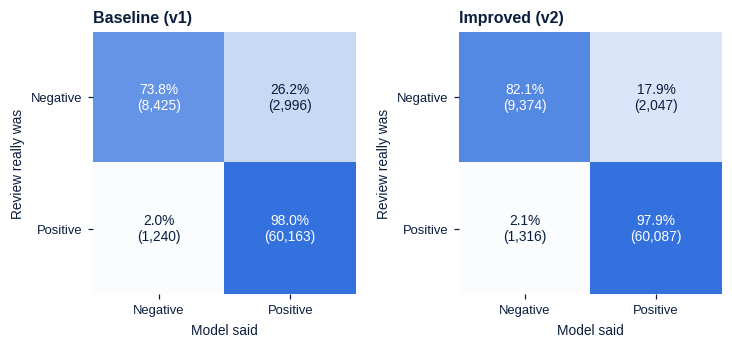

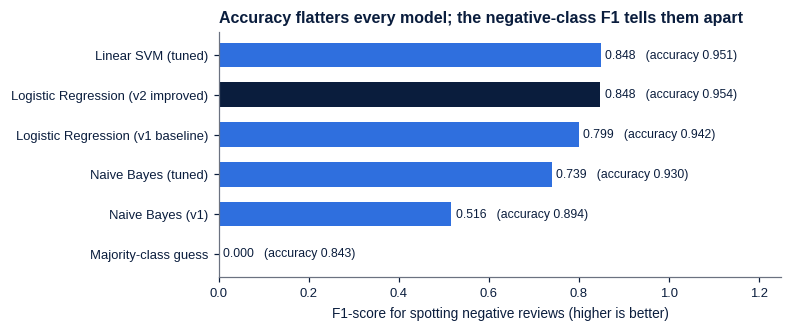

In [17]:
# Confusion matrices: v1 baseline vs v2 improved (rows = what the review really was, columns = what the model said)
cmap = LinearSegmentedColormap.from_list("blue", ["#FFFFFF", POS])
fig, axes = plt.subplots(1, 2, figsize=(6.8, 3.2))
for ax, res, ttl in ((axes[0], [r for r in all_results if r["model"].endswith("(v1 baseline)")][0], "Baseline (v1)"),
                     (axes[1], res_lr2, "Improved (v2)")):
    cm = np.array(res["cm"]); pct = cm / cm.sum(axis=1, keepdims=True) * 100
    ax.imshow(pct, cmap=cmap, vmin=0, vmax=100)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{pct[i, j]:.1f}%\n({cm[i, j]:,})", ha="center", va="center",
                    color="white" if pct[i, j] > 55 else INK, fontsize=9)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Negative", "Positive"]); ax.set_yticks([0, 1]); ax.set_yticklabels(["Negative", "Positive"])
    ax.set_xlabel("Model said"); ax.set_ylabel("Review really was"); ax.set_title(ttl)
    for s in ax.spines.values():
        s.set_visible(False)
fig.tight_layout()
save(fig, "fig08_confusion_matrices.png")

# Model comparison on the metric the business cares about most: finding the unhappy customers
cmp_plot = comp_tbl.sort_values("neg_f1")
fig, ax = plt.subplots(figsize=(6.6, 2.9))
colors = [INK if m == R["final_model"] else POS for m in cmp_plot.model]
ax.barh(cmp_plot.model, cmp_plot.neg_f1, color=colors, height=0.62)
for y, (f1v, acc) in enumerate(zip(cmp_plot.neg_f1, cmp_plot.accuracy)):
    ax.text(f1v + 0.01, y, f"{f1v:.3f}   (accuracy {acc:.3f})", va="center", fontsize=8)
ax.set_xlim(0, 1.25); ax.set_xlabel("F1-score for spotting negative reviews (higher is better)")
ax.set_title("Accuracy flatters every model; the negative-class F1 tells them apart")
save(fig, "fig09_model_comparison.png")

Strongest complaint signals: not worth, worst, disappointing, not recommend, yuck, disappointment, not, not tasty, definitely not, disappointed, not happy, not best, not impressed, terrible, tasteless
Strongest praise signals   : great, not disappointed, delicious, excellent, awesome, good, best, perfect, yummy, yum, amazing, love, wonderful, fantastic, not bad


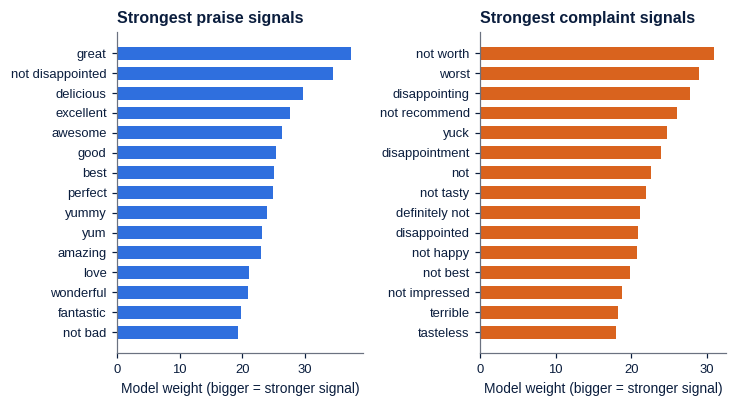

In [18]:
# What did the final model learn? Largest positive and negative coefficients (log-odds contribution to "positive")
names = np.array(vec2.get_feature_names_out())
coef = lr2.coef_[0]
order = np.argsort(coef)
top_neg_terms = [(names[i], float(coef[i])) for i in order[:15]]
top_pos_terms = [(names[i], float(coef[i])) for i in order[::-1][:15]]
R["coef_neg"], R["coef_pos"] = top_neg_terms, top_pos_terms
print("Strongest complaint signals:", ", ".join(w for w, _ in top_neg_terms))
print("Strongest praise signals   :", ", ".join(w for w, _ in top_pos_terms))

fig, axes = plt.subplots(1, 2, figsize=(6.8, 3.8))
w, v = zip(*top_pos_terms[::-1]); axes[0].barh(w, v, color=POS, height=0.65); axes[0].set_title("Strongest praise signals")
w, v = zip(*top_neg_terms[::-1]); axes[1].barh(w, [abs(x) for x in v], color=NEG, height=0.65); axes[1].set_title("Strongest complaint signals")
for ax in axes:
    ax.set_xlabel("Model weight (bigger = stronger signal)")
fig.tight_layout()
save(fig, "fig10_model_terms.png")

In [19]:
# Error analysis. Which reviews does the final model get wrong?
te = test_df.copy()
te["pred"] = pred2
te["wrong"] = te.pred != te.label
err_by_star = te.groupby("Score").wrong.agg(["mean", "size"])
err_by_star["mean"] *= 100
R["error_by_star"] = {int(k): {"error_pct": float(r["mean"]), "n": int(r["size"])} for k, r in err_by_star.iterrows()}
print("Error rate by star rating (%):"); print(err_by_star.round(2).to_string())

fp = te[(te.label == 0) & (te.pred == 1)].sample(6, random_state=SEED)      # complaints the model read as praise
fn = te[(te.label == 1) & (te.pred == 0)].sample(6, random_state=SEED)      # praise the model read as complaints
ex = pd.concat([fp.assign(kind="Complaint read as praise"), fn.assign(kind="Praise read as complaint")])
ex[["kind", "Score", "Summary", "Text"]].to_csv(OUT / "error_examples.csv", index=False)
for r in ex.itertuples():
    print(f"[{r.kind} | {r.Score} stars] {r.Summary} :: {r.Text[:240].replace(chr(10), ' ')}")

# Neutral 3-star reviews were never used for training. Where does the model put them?
neu = df[df.label == -1]
neu_pred = lr2.predict(vec2.transform(neu.clean))
R["neutral_pred_positive_pct"] = float((neu_pred == 1).mean() * 100)
R["neutral_n"] = len(neu)
print(f"\n3-star reviews predicted positive: {R['neutral_pred_positive_pct']:.1f}% of {len(neu):,}")
dump()

Error rate by star rating (%):
        mean   size
Score              
1      12.33   7135
2      27.23   4286
4       5.62  11206
5       1.37  50197
[Complaint read as praise | 1 stars] Dented Cans!!! :: If I was reviewing only the beans, I give them 5 stars!  The beans are excellent.  However, ordering them from Amazon is not.  My beans arrived with at least one dent in every can.  After all this time, Amazon hasn't figured out how to ship
[Complaint read as praise | 2 stars] Sorry, I didn't agree with y'all :: These fell short on flavor, sweetness, and satisfaction. As other reviewers have mentioned, they do have a bit of an after taste too.  Trader Joe's are way better and at a much better price.<br /><br />For those that absolutely want less ca
[Complaint read as praise | 2 stars] Good taste... expires too soon! :: First off let me say that the product (Reese Homestyle Garlic and Cheese Croutons) were great.  They were light, crunchy and very tasty.<br /><br />The major negative 


3-star reviews predicted positive: 60.4% of 29,768


In [20]:
# Robustness: train on the OLDEST 80% of reviews and test on the NEWEST 20% (closer to real use than a random split)
srt = sent.sort_values("Time").reset_index(drop=True)
cut = int(len(srt) * 0.8)
t_tr, t_te = srt.iloc[:cut], srt.iloc[cut:]
cut_date = str(pd.to_datetime(t_te.Time.min(), unit="s").date())
t0 = time.time()
vt = TfidfVectorizer(min_df=5, max_features=200000, ngram_range=(1, 2), sublinear_tf=True)
Xt_tr = vt.fit_transform(t_tr.clean); Xt_te = vt.transform(t_te.clean)
mt = LogisticRegression(C=bl.p1, class_weight=cw_lr, max_iter=1000).fit(Xt_tr, t_tr.label)
res_time = metrics("Logistic Regression v2, time-based split", t_te.label.values, mt.predict(Xt_te), mt.decision_function(Xt_te))
res_time["test_starts"] = cut_date
R["temporal"] = res_time
print(f"Test period starts {cut_date}. accuracy={res_time['accuracy']:.4f} macroF1={res_time['macro_f1']:.4f} "
      f"neg F1={res_time['neg_f1']:.4f}  ({time.time()-t0:.0f}s)")
dump()

Test period starts 2012-05-15. accuracy=0.9534 macroF1=0.9164 neg F1=0.8608  (71s)


## 7. Theme discovery with LDA topic modelling
LDA is fitted **separately** on negative and on positive reviews, so one set of themes describes concerns and the other describes praise.
The number of topics is chosen from {4, 6, 8, 10} by NPMI coherence (do the top words of a topic really appear together in reviews?).
Generic filler words are removed for this step only, so the topics describe subjects rather than tone.

In [21]:
TOPIC_STOP = sorted(STOP | NEGATIONS | {
    "like", "just", "really", "one", "get", "got", "would", "also", "even", "much", "use", "used", "buy", "bought",
    "product", "products", "amazon", "review", "time", "make", "made", "good", "great", "love", "best", "nice", "well",
    "better", "little", "bit", "try", "tried", "find", "found", "think", "going", "way", "thing", "things", "lot",
    "ve", "ll", "didn", "don", "doesn", "ordered", "order", "bag", "bags", "box", "price",
    "did", "does", "bad", "want", "wanted", "came", "know", "say", "said", "need", "thought", "purchase",
    "purchased", "buying", "item", "items", "taste", "tastes", "flavor", "flavors"})
# Note: "taste"/"flavor", "price", "box" and "bag" are removed from topic fitting only because they swamp topics; they are analyzed in the aspect table above.

def npmi_coherence(B, top_idx_list, n_docs):
    """Average NPMI over all word pairs in each topic's top words, using document co-occurrence."""
    eps, out = 1e-12, []
    for idx in top_idx_list:
        sub = B[:, idx]
        co = (sub.T @ sub).toarray() / n_docs
        p = np.diag(co)
        vals = []
        for i in range(len(idx)):
            for j in range(i + 1, len(idx)):
                pmi = np.log((co[i, j] + eps) / (p[i] * p[j] + eps))
                vals.append(pmi / (-np.log(co[i, j] + eps)))
        out.append(np.mean(vals))
    return float(np.mean(out))

def fit_topics(texts, label, ks=(4, 6, 8, 10), n_docs=40000):
    sample = texts.sample(min(n_docs, len(texts)), random_state=SEED)
    cv = CountVectorizer(max_df=0.4, min_df=20, max_features=6000, stop_words=TOPIC_STOP)
    Xc = cv.fit_transform(sample)
    B = (Xc > 0).astype(np.float32).tocsc()
    vocab = cv.get_feature_names_out()
    fits, scores = {}, []
    for k in ks:
        t0 = time.time()
        lda = LatentDirichletAllocation(n_components=k, learning_method="online", max_iter=8, batch_size=2048,
                                        random_state=SEED, n_jobs=2).fit(Xc)
        tops = [np.argsort(c)[::-1][:10] for c in lda.components_]
        scores.append((k, npmi_coherence(B, tops, B.shape[0])))
        fits[k] = (lda, tops)
        print(f"  {label}: k={k} coherence={scores[-1][1]:.4f} ({time.time()-t0:.0f}s)")
    best_k = max(scores, key=lambda s: s[1])[0]
    lda, tops = fits[best_k]
    dom = lda.transform(Xc).argmax(axis=1)
    prev = np.bincount(dom, minlength=best_k) / len(dom) * 100
    table = pd.DataFrame({"topic": range(1, best_k + 1), "prevalence_pct": prev,
                          "top_words": [", ".join(vocab[i] for i in t) for t in tops]}).sort_values("prevalence_pct", ascending=False)
    return table.reset_index(drop=True), scores, best_k, len(sample)

topics_neg, coh_neg, k_neg, n_neg_s = fit_topics(df.loc[df.label == 0, "clean"], "negative")
topics_pos, coh_pos, k_pos, n_pos_s = fit_topics(df.loc[df.label == 1, "clean"], "positive")
topics_neg.to_csv(OUT / "topics_negative.csv", index=False); topics_pos.to_csv(OUT / "topics_positive.csv", index=False)
R["topics"] = {"negative": {"k": k_neg, "coherence": coh_neg, "sample": n_neg_s, "table": topics_neg.to_dict(orient="records")},
               "positive": {"k": k_pos, "coherence": coh_pos, "sample": n_pos_s, "table": topics_pos.to_dict(orient="records")}}
pd.set_option("display.max_colwidth", 120)
print(f"\nNEGATIVE reviews: {k_neg} topics"); print(topics_neg.round(1).to_string(index=False))
print(f"\nPOSITIVE reviews: {k_pos} topics"); print(topics_pos.round(1).to_string(index=False))
dump()

  negative: k=4 coherence=0.1485 (66s)


  negative: k=6 coherence=0.1347 (65s)


  negative: k=8 coherence=0.1403 (66s)


  negative: k=10 coherence=0.1530 (65s)


  positive: k=4 coherence=0.1359 (64s)


  positive: k=6 coherence=0.1235 (67s)


  positive: k=8 coherence=0.1476 (61s)


  positive: k=10 coherence=0.1488 (57s)



NEGATIVE reviews: 10 topics
 topic  prevalence_pct                                                                            top_words
     4            14.5                    mix, smell, sauce, soup, cheese, tasted, free, stuff, eat, gluten
     8            13.3                chocolate, candy, cookies, bars, stale, bar, hard, chips, butter, eat
     9            12.7 received, cans, company, date, arrived, opened, packaging, customer, return, service
     2            10.9                   coffee, cup, cups, beans, bitter, vanilla, weak, roast, blend, hot
     1            10.9                       food, dog, dogs, cat, eat, treats, cats, china, chicken, treat
     5            10.7      oz, store, shipping, pack, description, picture, size, received, package, local
     7             8.4      sugar, water, drink, sweet, syrup, juice, artificial, bottle, fruit, aftertaste
    10             6.4                  tea, green, cereal, new, milk, teas, changed, black, chai, original

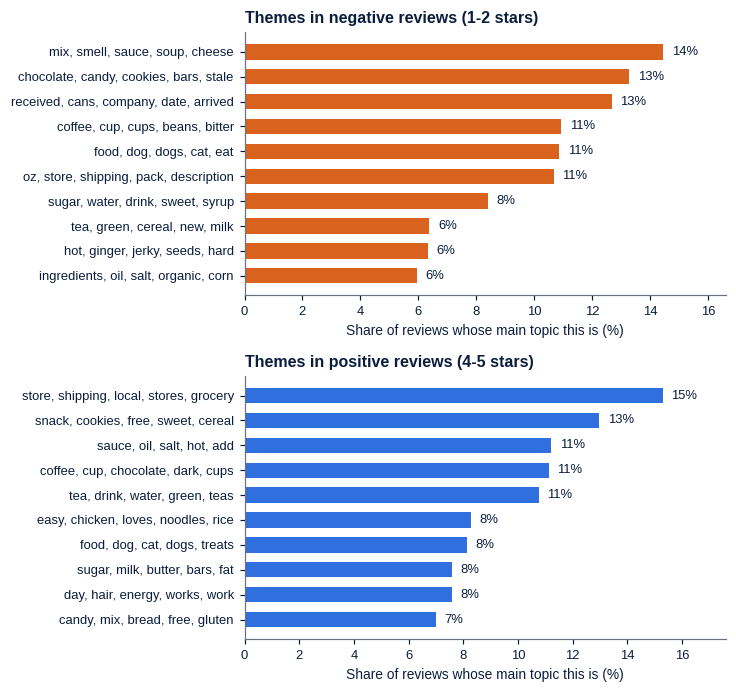

In [22]:
# Topic prevalence charts, labelled with each topic's leading words (the report names the topics from these words)
fig, axes = plt.subplots(2, 1, figsize=(6.8, 6.4))
for ax, tb, colr, ttl in ((axes[0], topics_neg, NEG, "Themes in negative reviews (1-2 stars)"),
                          (axes[1], topics_pos, POS, "Themes in positive reviews (4-5 stars)")):
    t = tb.iloc[::-1]
    labels = [", ".join(w.split(", ")[:5]) for w in t.top_words]
    ax.barh(labels, t.prevalence_pct, color=colr, height=0.62)
    for y, v in enumerate(t.prevalence_pct):
        ax.text(v + 0.3, y, f"{v:.0f}%", va="center", fontsize=8.5)
    ax.set_xlim(0, t.prevalence_pct.max() * 1.15); ax.set_xlabel("Share of reviews whose main topic this is (%)"); ax.set_title(ttl)
fig.tight_layout()
save(fig, "fig11_topics.png")

## 8. Wrap-up

In [23]:
dump()
print("Figures saved:", ", ".join(sorted(p.name for p in FIG.glob("*.png"))))
print("Results file :", OUT / "results.json")

Figures saved: fig00_pipeline.png, fig01_score_distribution.png, fig02_trend_by_year.png, fig03_review_length.png, fig04_top_words.png, fig05_wordclouds.png, fig06_distinctive_words.png, fig07_aspect_risk.png, fig08_confusion_matrices.png, fig09_model_comparison.png, fig10_model_terms.png, fig11_topics.png
Results file : /home/claude/ice3/outputs/results.json
